# CNN Model Development - NIH Chest X-ray Classification

### Objective

This notebook develops a simple Convolutional Neural Network (CNN) using PyTorch to classify chest X-ray images into two categories: Effusion and No Finding.

### Execution Plan

In this notebook, we will
1. Load existing dataset and construct PyTorch DataLoaders
2. Build CNN architecture
3. Inspect model parameters and tensor dimensions
4. Train CNN using native PyTorch training loop
5. Evaluate model performance on validation and test sets
6. Compare CNN against MLP
7. Experiment with image augmentation and assess its impact on model performance

### Learning Focus

Understand how convolutional layers, feature maps, pooling, and fully connected layers work together to extract image features and perform classification. 

### Limitations

This is an educational project and is not intended for clinical diagnosis.

## 01. Dataset

NIH ChestX-ray14 subset of 3241 images, will be split following the MLP model for consistency and to allow for comparisons between the 2 models.

In [1]:
import torch
import pandas as pd
import numpy as np
import random

# Add random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
# Encourage deterministic behavior for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Load preprocessed tensors
data = torch.load(
    "../../data/processed/mlp_images_64x64.pt",
    map_location="cpu",
    weights_only=True)

X = data["X"]
y = data["y"]
image_names = data["image_names"]
patient_ids = data["patient_ids"]  
splits = data["splits"]  

print("Images:", X.shape)
print("Labels:", y.shape)
print("Number of patients:", len(patient_ids))
print("Number of splits:", len(splits))
print("Data type:", X.dtype)
print("Minimum:", X.min().item())
print("Maximum:", X.max().item())

# Load dataset metadata
df = pd.read_csv("../../data/processed/mlp_dataset.csv")
print("Columns:", df.columns.tolist())
print(f"Split distribution: {df.groupby(['Split', 'Label']).size()}")


Images: torch.Size([3241, 1, 64, 64])
Labels: torch.Size([3241])
Number of patients: 3241
Number of splits: 3241
Data type: torch.float32
Minimum: 0.0
Maximum: 1.0
Columns: ['Image Index', 'Patient ID', 'Label', 'Split']
Split distribution: Split  Label
test   0         329
       1         150
train  0        1939
       1         269
val    0         486
       1          68
dtype: int64


## 02. Data Preparation

We will confirm that data for CNN model development is identical to the data used for MLP model development:
- 3241 images, with matching tensor and CSV 
- 2208 training, 554 validation, and 479 test images
- Labels encoded as 0 and 1
- Original patient-level splits preserved
- No need to preprocess or split data again

In [2]:
from collections import Counter

# Inspect split and label values
print("Split values:", Counter(splits))
print("Label values:", Counter(y.tolist()))

print("First 5 image names:", image_names[:5])
print("First 5 patient IDs:", patient_ids[:5])

# Verify CSV metadata
print("CSV columns:", df.columns.tolist())
print("Split and label distribution:")
print(df.groupby(["Split", "Label"]).size())
print("First 5 rows:")
display(df.head())

# Check tensor and CSV ordering match
print("Tensor images:", len(X))
print("CSV rows:", len(df))

print("Image names match:",
      image_names == df["Image Index"].tolist())

Split values: Counter({'train': 2208, 'val': 554, 'test': 479})
Label values: Counter({0: 2754, 1: 487})
First 5 image names: ['00000002_000.png', '00000005_000.png', '00000005_001.png', '00000005_002.png', '00000005_003.png']
First 5 patient IDs: [2, 5, 5, 5, 5]
CSV columns: ['Image Index', 'Patient ID', 'Label', 'Split']
Split and label distribution:
Split  Label
test   0         329
       1         150
train  0        1939
       1         269
val    0         486
       1          68
dtype: int64
First 5 rows:


,Image Index,Patient ID,Label,Split
0,00000002_000.png,2,0,train
1,00000005_000.png,5,0,train
2,00000005_001.png,5,0,train
3,00000005_002.png,5,0,train
4,00000005_003.png,5,0,train


Tensor images: 3241
CSV rows: 3241
Image names match: True


## 03. Model Architecture

### 3.1 Creating PyTorch Datasets and DataLoaders

Datasets store and provide access to individual sample and their labels.
DataLoader retrieves samples from the Dataset and groups them into batches. Training will be performed on these manageable subsets of data.

In [3]:
from torch.utils.data import TensorDataset, DataLoader, Subset

# Create a dataset containing images and labels
dataset = TensorDataset(X, y)

# Get indices for each split
train_idx = [i for i, s in enumerate(splits) if s == "train"]
val_idx = [i for i, s in enumerate(splits) if s == "val"]
test_idx = [i for i, s in enumerate(splits) if s == "test"]

# Create separate datasets
train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

# Dedicated random generator for reproducible shuffling
g = torch.Generator()
g.manual_seed(SEED)
# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=g,
    num_workers=0)
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0)
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Inspect 1 batch
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Labels in batch:", labels.unique())

Training batches: 69
Validation batches: 18
Test batches: 15
Image batch shape: torch.Size([32, 1, 64, 64])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
Labels in batch: tensor([0, 1])


There are 69 training batches, 18 validation batches, and 15 test batches of 32 images each. 

Each image has 1 channel (grayscale), 64 pixels in height and 64 pixels in width (64x64), with the labels containing corresponding diagnosis class for each image.

### 3.2 Building the CNN Architecture

1. First convolution layer (nn.Conv2d)
2. ReLU activation to introduce non-linearity
3. MaxPooling (nn.MaxPool)
4. Second convolution layer (nn.Conv2d)
5. ReLU activation
6. MaxPooling
7. nn.Flatten
8. nn.Linear

In [4]:
# Add repo root to Python's search path
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(PROJECT_ROOT))

print(PROJECT_ROOT)

import torch.nn as nn
from cnn.src.cnn_model import build_cnn_model

# CNN Model
torch.manual_seed(SEED)
model = build_cnn_model()

/Users/hweeenheah/Downloads/EDA_Resources/nih-chestxray-ml


## 04. Training CNN model

### 4.1 Configure Loss Function, Optimizer, and Device

In [5]:
import torch.optim as optim

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
model = model.to(device)

# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

Using device: cpu


### 4.2 Training Loop for 10 epochs

In [6]:
import copy 

NUM_EPOCHS = 10
cnn_train_losses = []
cnn_val_losses = []
best_val_loss = float("inf")
best_model_state = None

# Reset training randomness for reproducibility
torch.manual_seed(SEED)
train_loader.generator = torch.Generator().manual_seed(SEED)

for epoch in range(NUM_EPOCHS):
    # Training
    model.train()
    running_train_loss = 0.0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item()
    epoch_train_loss = running_train_loss / len(train_loader)
    cnn_train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_val_loss += loss.item()
    epoch_val_loss = running_val_loss / len(val_loader)
    cnn_val_losses.append(epoch_val_loss)

    # Best model with least loss
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1

    # Results
    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Val Loss: {epoch_val_loss:.4f}"
    )            
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

# Restore best model
model.load_state_dict(best_model_state)

Epoch [1/10] Train Loss: 0.3814 Val Loss: 0.4131
Epoch [2/10] Train Loss: 0.3548 Val Loss: 0.3820
Epoch [3/10] Train Loss: 0.3427 Val Loss: 0.3550
Epoch [4/10] Train Loss: 0.3409 Val Loss: 0.3360
Epoch [5/10] Train Loss: 0.3355 Val Loss: 0.3374
Epoch [6/10] Train Loss: 0.3246 Val Loss: 0.3271
Epoch [7/10] Train Loss: 0.3159 Val Loss: 0.3294
Epoch [8/10] Train Loss: 0.3070 Val Loss: 0.3414
Epoch [9/10] Train Loss: 0.3014 Val Loss: 0.3203
Epoch [10/10] Train Loss: 0.2953 Val Loss: 0.3252
Best epoch: 9
Best validation loss: 0.3203


<All keys matched successfully>

Validation loss reaches its lowest point at epoch 9 (0.3203), while training loss decreases continually. This is an early sign of overfitting. 

Hence, we have saved and restored the best model (epoch 9), and will be using its weights. This model will be used for evaluation, rather than the final epoch 10 model. 

Next, we will evaluate this model on the validation dataset.

## 05. Evaluate CNN Model

Evaluate validation predictions

In [7]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

# Switch model to evaluation mode
model.eval()

cnn_predictions = []
cnn_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        # Select class with higher logit
        predictions = torch.argmax(outputs, dim=1)
        cnn_predictions.extend(predictions.cpu().numpy())
        cnn_labels.extend(labels.cpu().numpy())

# Confusion matrix
cm = confusion_matrix(cnn_labels, cnn_predictions)
print(cm)

# Evaluation metrics
accuracy = accuracy_score(cnn_labels, cnn_predictions)
classification_metrics = classification_report(cnn_labels, cnn_predictions, target_names=["No Finding", "Effusion"], zero_division=0)
precision = precision_score(cnn_labels, cnn_predictions, zero_division=0)
recall = recall_score(cnn_labels, cnn_predictions, zero_division=0)
f1 = f1_score(cnn_labels, cnn_predictions, zero_division=0)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 score: {f1:.4f}")
print("Classification Report:", classification_metrics)

[[460  26]
 [ 52  16]]
Accuracy: 0.8592
Precision: 0.3810
Recall: 0.2353
F1 score: 0.2909
Classification Report:               precision    recall  f1-score   support

  No Finding       0.90      0.95      0.92       486
    Effusion       0.38      0.24      0.29        68

    accuracy                           0.86       554
   macro avg       0.64      0.59      0.61       554
weighted avg       0.83      0.86      0.84       554



Our current CNN model (epoch 9) predicted 460 TNs, 52 FNs, 26 FPs, and 16 TPs. It has detected only 16 out of 68 actual Effusion images, missing the remaining 52. It correctly identified 460 of 486 No Finding images. 

This model is good at recognising "No Finding", but struggles with the "Effusion" minority class. 

| Metrics | Baseline MLP | Baseline CNN |
| ------- | --- | --- |
|Accuracy | 0.8755 | 0.8592 |
|Precision | 0.00 | 0.3810 |
|Recall | 0.00 | 0.2353 |
|F1 | 0.00 | 0.2909 |

Compared to the MLP model, the CNN model shows improvement in the precision, recall, and F1 score, suggesting that it has learned more useful image features through convolutional filters. Although its accuracy is slightly lower, we should remember that the MLP model predicted all images as "No Finding". Its accuracy was therefore driven by the majority class, rather than its ability to detect Effusion. 

Next, we will attempt to handle class imbalance using class weighting to see whether it improves the CNN model's ability to detect Effusion.

## 06. Experiments: Handling Class Imbalance

The training dataset contains 1939 "No Finding" and 269 "Effusion" images. That's a 7.2:1 class imbalance. 

### 6.1 Introduce Class Weights

With class weighting, the loss function will penalise mistakes on Effusion more heavily. 

In [8]:
class_counts = torch.bincount(y[train_idx])
class_weights = len(train_idx) / (2 * class_counts.float())
print("Class counts:", class_counts)
print("Class weights:", class_weights)
# Effusion receives much higher weight due to it being minority class

Class counts: tensor([1939,  269])
Class weights: tensor([0.5694, 4.1041])


### 6.2 Train Weighted CNN

In [9]:
# Start with fresh CNN model so it doesn't retain what it learned during baseline training
torch.manual_seed(SEED)
weighted_model = build_cnn_model()
weighted_model = weighted_model.to(device)

# Optimizer
optimizer = optim.Adam(weighted_model.parameters(), lr=0.001)

# Update loss function to penalise incorrect effusion predictions more heavily
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

In [10]:
# Retrain new weighted CNN model using same 10-epoch training and validation loop
NUM_EPOCHS = 10
weighted_cnn_train_losses = []
weighted_cnn_val_losses = []
weighted_best_val_loss = float("inf")
weighted_best_model_state = None

# Reset training randomness for reproducibility
torch.manual_seed(SEED)
train_loader.generator = torch.Generator().manual_seed(SEED)

for epoch in range(NUM_EPOCHS):
    # Training
    weighted_model.train()
    weighted_running_train_loss = 0.0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = weighted_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        weighted_running_train_loss += loss.item()
    weighted_epoch_train_loss = weighted_running_train_loss / len(train_loader)
    weighted_cnn_train_losses.append(weighted_epoch_train_loss)

    # Validation
    weighted_model.eval()
    weighted_running_val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = weighted_model(images)
            loss = criterion(outputs, labels)
            weighted_running_val_loss += loss.item()
    weighted_epoch_val_loss = weighted_running_val_loss / len(val_loader)
    weighted_cnn_val_losses.append(weighted_epoch_val_loss)

    # Best model with least loss
    if weighted_epoch_val_loss < weighted_best_val_loss:
        weighted_best_val_loss = weighted_epoch_val_loss
        weighted_best_model_state = copy.deepcopy(weighted_model.state_dict())
        weighted_best_epoch = epoch + 1

    # Results
    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {weighted_epoch_train_loss:.4f} "
        f"Val Loss: {weighted_epoch_val_loss:.4f}"
    )            
print(f"Best epoch: {weighted_best_epoch}")
print(f"Best validation loss: {weighted_best_val_loss:.4f}")

# Restore best model
weighted_model.load_state_dict(weighted_best_model_state)

Epoch [1/10] Train Loss: 0.6740 Val Loss: 0.5929
Epoch [2/10] Train Loss: 0.6234 Val Loss: 0.5679
Epoch [3/10] Train Loss: 0.6104 Val Loss: 0.5340
Epoch [4/10] Train Loss: 0.5934 Val Loss: 0.5620
Epoch [5/10] Train Loss: 0.5603 Val Loss: 0.5277
Epoch [6/10] Train Loss: 0.5563 Val Loss: 0.5089
Epoch [7/10] Train Loss: 0.5384 Val Loss: 0.5105
Epoch [8/10] Train Loss: 0.5392 Val Loss: 0.4945
Epoch [9/10] Train Loss: 0.5140 Val Loss: 0.4995
Epoch [10/10] Train Loss: 0.5197 Val Loss: 0.4969
Best epoch: 8
Best validation loss: 0.4945


<All keys matched successfully>

Validation loss reaches its lowest point at epoch 8 (0.4945), then fluctuated, while training loss continued decreasing. This may suggest some overfitting towards the later epochs. (Note: weighted loss (0.4945) and unweighted loss (0.3203) are not directly comparable because class weights changes the loss calculation itself.) 

Hence, we have saved and restored the best model (epoch 8), and will be using its weights. This model will be used for evaluation, rather than the final epoch 10 model. 

Next, we will evaluate this model on the validation dataset.

### 6.3 Evaluate Weighted CNN

In [12]:
# Switch model to evaluation mode
weighted_model.eval()

weighted_cnn_predictions = []
weighted_cnn_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = weighted_model(images)
        # Select class with higher logit
        predictions = torch.argmax(outputs, dim=1)
        weighted_cnn_predictions.extend(predictions.cpu().numpy())
        weighted_cnn_labels.extend(labels.cpu().numpy())

# Confusion matrix
cm = confusion_matrix(weighted_cnn_labels, weighted_cnn_predictions)
print(cm)

# Evaluation metrics
accuracy = accuracy_score(weighted_cnn_labels, weighted_cnn_predictions)
precision = precision_score(weighted_cnn_labels, weighted_cnn_predictions, zero_division=0)
recall = recall_score(weighted_cnn_labels, weighted_cnn_predictions, zero_division=0)
f1 = f1_score(weighted_cnn_labels, weighted_cnn_predictions, zero_division=0)
classification_metrics = classification_report(weighted_cnn_labels, weighted_cnn_predictions, target_names=["No Finding", "Effusion"], zero_division=0)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 score: {f1:.4f}")
print("Classification Report:", classification_metrics)

[[418  68]
 [ 30  38]]
Accuracy: 0.8231
Precision: 0.3585
Recall: 0.5588
F1 score: 0.4368
Classification Report:               precision    recall  f1-score   support

  No Finding       0.93      0.86      0.90       486
    Effusion       0.36      0.56      0.44        68

    accuracy                           0.82       554
   macro avg       0.65      0.71      0.67       554
weighted avg       0.86      0.82      0.84       554



|Validation metric | Weighted MLP | Baseline CNN | Weighted CNN |
| ------ | -------| ------| ------- |
|Accuracy | 72.02% | 85.92% |  82.31% |
|Precision | 28.78% | 38.10% | 35.85% |
|Recall | 86.76% | 23.53% | 55.88% |
|F1	| 43.22% | 29.09% | 43.68% |

The weighted CNN model (epoch 8) correctly identified 38 out of 68 actual Effusion images (TP), missing 30 (FN), as compared with 52 missed Effusion images in the baseline CNN model. However, it incorrectly classified 68 No Finding images as Effusion (FP). 

Applying class weight increased Effusion recall substantially, from 23.53% to 55.88%, while precision decreased only slightly, from 38.10% to 35.85%. This demonstrates the precision-recall trade-off: the model became more sensitive to Effusion, but generated more false positives.

The baseline CNN model was biased towards predicting the majority class. By assigning a heavier penalty to incorrect Effusion predictions, class weighting encouraged the model to pay more attention to the minority class. The CNN architecture remained unchanged, so this improvement was not due to learning new image features, but rather to optimising the same architecture under a different loss function.

When comparing the weighted MLP and weighted CNN, the MLP achieved higher Effusion recall (86.76% vs 55.88%), whereas the CNN achieved higher precision (35.85% vs 28.78%) and F1-score (43.68% vs 43.22%). This suggests that the CNN model offers a slightly better balance between precision and recall, although the difference in F1-score is small. Neither model clearly dominates across all metrics.

## 07. Image Augmentation

Weighted CNN + Image Augmentation

Keeping in mind that we are dealing with medical images here, we will introduce mild transformations to training images:
Rotation: +- 5 degrees
Translation: +- 3%
Scaling: 95 to 105%
Flipping disabled to account for anatomical laterality.
The CNN architecture, class weights, optimiser, and learning rate will remain unchanged.

### 7.1 Apply image augmentation to training dataset

Image Augmentation to only training dataset, keeping the validation and test datasets unchanged.

In [13]:
# Set up Augmentation
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# Mild Image Augmentation
train_transforms = transforms.RandomAffine(
    degrees=5,
    translate=(0.03, 0.03),
    scale=(0.95, 1.05))

# Custom dataset: applies augmentation only when retrieving training images
class AugmentedDataset(Dataset):
    def __init__(self, X, y, indices, transform=None):
        self.X = X
        self.y = y
        self.indices = indices
        self.transform = transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, idx):
        actual_idx = self.indices[idx]
        image = self.X[actual_idx]
        label = self.y[actual_idx]
        if self.transform:
            image = self.transform(image)
        return image, label   

# DataLoaders
# Augmentation applied to training images only
augmented_train_dataset = AugmentedDataset(X, y, train_idx, transform=train_transforms)
# Validation and test remain unchanged
val_dataset = AugmentedDataset(X, y, val_idx)
test_dataset = AugmentedDataset(X, y, test_idx)
# Create new DataLoaders
train_loader = DataLoader(
    augmented_train_dataset, 
    batch_size=32, 
    shuffle=True)
val_loader = DataLoader(
    val_dataset, 
    batch_size=32, 
    shuffle=False)
test_loader = DataLoader(
    test_dataset, 
    batch_size=32, 
    shuffle=False)

# Verify new DataLoaders
images, labels = next(iter(train_loader))
print("Training batch:", images.shape)
print("Validation batch:", next(iter(val_loader))[0].shape)
print("Test batch:", next(iter(test_loader))[0].shape)

Training batch: torch.Size([32, 1, 64, 64])
Validation batch: torch.Size([32, 1, 64, 64])
Test batch: torch.Size([32, 1, 64, 64])


### 7.2 Train the augmented weighted CNN

Keeping the same CNN architecture, class weights, adam optimizer, learning rate, batch size, and epoch size.

In [14]:
# Fresh CNN model with same architecture
torch.manual_seed(SEED)
aug_model = build_cnn_model().to(device)

# Weighted loss
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

# Fresh optimizer
optimizer = optim.Adam(aug_model.parameters(), lr=0.001)

In [15]:
# Training settings
NUM_EPOCHS = 10
aug_train_losses = []
aug_val_losses = []
aug_best_val_loss = float("inf")
aug_best_model_state = None

# Reset training randomness for reproducibility
torch.manual_seed(SEED)
train_loader.generator = torch.Generator().manual_seed(SEED)

# Train augmented, weighted CNN
for epoch in range(NUM_EPOCHS):
    # Training
    aug_model.train()
    aug_running_train_loss = 0.0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = aug_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        aug_running_train_loss += loss.item()
    aug_epoch_train_loss = aug_running_train_loss / len(train_loader)
    aug_train_losses.append(aug_epoch_train_loss)

    # Validation
    aug_model.eval()
    aug_running_val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = aug_model(images)
            loss = criterion(outputs, labels)
            aug_running_val_loss += loss.item()
    aug_epoch_val_loss = aug_running_val_loss / len(val_loader)
    aug_val_losses.append(aug_epoch_val_loss)

    # Best model with least loss
    if aug_epoch_val_loss < aug_best_val_loss:
        aug_best_val_loss = aug_epoch_val_loss
        aug_best_model_state = copy.deepcopy(aug_model.state_dict())
        aug_best_epoch = epoch + 1

    # Results
    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {aug_epoch_train_loss:.4f} "
        f"Val Loss: {aug_epoch_val_loss:.4f}"
    )            
print(f"Best epoch: {aug_best_epoch}")
print(f"Best validation loss: {aug_best_val_loss:.4f}")

# Restore best model
aug_model.load_state_dict(aug_best_model_state)

Epoch [1/10] Train Loss: 0.6954 Val Loss: 0.6537
Epoch [2/10] Train Loss: 0.6557 Val Loss: 0.5656
Epoch [3/10] Train Loss: 0.6293 Val Loss: 0.5615
Epoch [4/10] Train Loss: 0.6125 Val Loss: 0.5572
Epoch [5/10] Train Loss: 0.6165 Val Loss: 0.5629
Epoch [6/10] Train Loss: 0.6068 Val Loss: 0.5310
Epoch [7/10] Train Loss: 0.5951 Val Loss: 0.5546
Epoch [8/10] Train Loss: 0.5975 Val Loss: 0.6069
Epoch [9/10] Train Loss: 0.5918 Val Loss: 0.5376
Epoch [10/10] Train Loss: 0.5772 Val Loss: 0.5534
Best epoch: 6
Best validation loss: 0.5310


<All keys matched successfully>

In [20]:
# Keep best model for further evaluation
import copy
aug_cnn_model = copy.deepcopy(aug_model)

Validation loss reaches its lowest point at epoch 6 (0.5310), fluctuating considerably during training, while training loss decreased from 0.6954 to 0.5772. 

Comparing the current augmented and weighted CNN to the previous weighted CNN, the best validation loss for augmented and weighted CNN is 0.5310, and 0.4945 for the weighted CNN. (Note: weighted losses are comparable as both experiments used the same class weights and loss functions.) Although the augmented model has a slightly higher validation loss, we should not reject augmentation based on this alone. We will further evaluate the augmented model to see whether it improves Effusion detection.

We have saved and restored the best model (epoch 6), and will be using its weights. This model will be used for evaluation, rather than the final epoch 10 model. 

Next, we will evaluate this augmented, weighted model on the validation dataset.

### 7.3 Evaluate the augmented weighted CNN

Evaluate its validation confusion matrix, accuracy, precision, recall, and F1-score.

In [16]:
# Switch model to evaluation mode
aug_model.eval()

aug_predictions = []
aug_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = aug_model(images)
        # Select class with higher logit
        predictions = torch.argmax(outputs, dim=1)
        aug_predictions.extend(predictions.cpu().numpy())
        aug_labels.extend(labels.cpu().numpy())

# Confusion matrix
cm = confusion_matrix(aug_labels, aug_predictions)
print(cm)

# Evaluation metrics
accuracy = accuracy_score(aug_labels, aug_predictions)
precision = precision_score(aug_labels, aug_predictions, zero_division=0)
recall = recall_score(aug_labels, aug_predictions, zero_division=0)
f1 = f1_score(aug_labels, aug_predictions, zero_division=0)
classification_metrics = classification_report(aug_labels, aug_predictions, target_names=["No Finding", "Effusion"], zero_division=0)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 score: {f1:.4f}")
print("Classification Report:", classification_metrics)

[[388  98]
 [ 19  49]]
Accuracy: 0.7888
Precision: 0.3333
Recall: 0.7206
F1 score: 0.4558
Classification Report:               precision    recall  f1-score   support

  No Finding       0.95      0.80      0.87       486
    Effusion       0.33      0.72      0.46        68

    accuracy                           0.79       554
   macro avg       0.64      0.76      0.66       554
weighted avg       0.88      0.79      0.82       554



|Validation metric	| Weighted CNN | Augmented & Weighted CNN|
| ------ | -------| ------|
|Accuracy | 82.31% | 78.88% |
|Precision | 35.85% | 33.33% |
|Recall | 55.88% | 72.06% |
|F1	| 43.68% | 45.58% |
|Best validation loss| 0.4945 | 0.5310 |

The augmented and weighted CNN model (best epoch-6) correctly identified 49 out of 68 actual Effusion images (TP), only missing 19 (FN). This is an improvement over the weighted CNN model, which identified 38 Effusion images and missed 30. However, the augmented model also incorrectly classified 98 No Finding images as Effusion (FP), compared with 68 for the weighted CNN model. This indicates that augmentation increased the model's tendency to predict Effusion, improving recall from 55.88% to 72.06%, but reducing precision from 35.85% to 33.33%. 

Despite the lower precision and higher validation loss (0.5310 vs 0.4945), the augmented model achieved a slightly higher F1-score (45.58% vs 43.68%), suggesting a modest improvement in balancing precision and recall. Overall, augmentation appears to have helped the model identify more Effusion cases, although this came at the cost of more false positives. The improvement is relatively small, so further experiments would be needed to establish whether augmentation provides a consistent benefit.

## 08. Select best CNN model

Compare experiments, select best model based on validation performance, especially effusion detection

### 8.1 Training and Validation Loss Curves

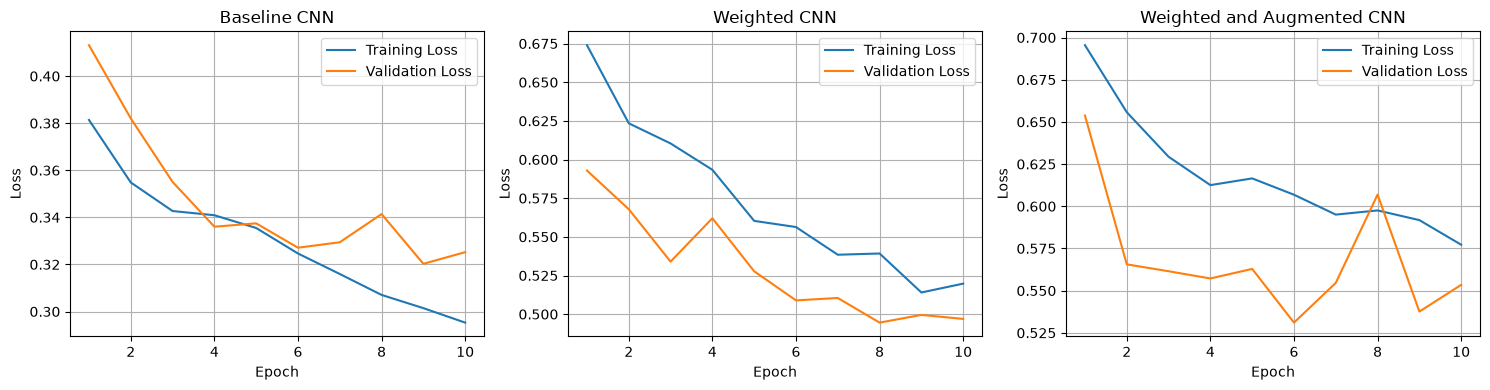

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

epochs = range(1, 11)

# Baseline CNN
axes[0].plot(epochs, cnn_train_losses, label="Training Loss")
axes[0].plot(epochs, cnn_val_losses, label="Validation Loss")
axes[0].set_title("Baseline CNN")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Weighted CNN
axes[1].plot(epochs, weighted_cnn_train_losses, label="Training Loss")
axes[1].plot(epochs, weighted_cnn_val_losses, label="Validation Loss")
axes[1].set_title("Weighted CNN")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

# Weighted and Augmented CNN
axes[2].plot(epochs, aug_train_losses, label="Training Loss")
axes[2].plot(epochs, aug_val_losses, label="Validation Loss")
axes[2].set_title("Weighted and Augmented CNN")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

### 8.2 Validation metric comparison

|Validation metric | Baseline CNN | Weighted CNN | Augmented & Weighted CNN |
| ------ | ----| -------| ------|
|Accuracy | 85.92% | 82.31% | 78.88% |
|Precision | 38.10% | 35.85% | 33.33% |
|Recall | 23.53% | 55.88% | 72.06% |
|F1	| 29.09% | 43.68% | 45.58% |

Although the baseline CNN achieves the highest accuracy (85.92%), its recall is only 23.53%, indicating that it misses 3 out of 4 Effusion cases.

The augmented and weighted CNN achieves the highest recall (72.06%), indicating that it detects the greatest proportion of actual Effusion cases. However, this comes at the cost of lower precision (33.33%) compared to the other models, suggesting that it produces more false positives. 

Although the weighted CNN achieves higher accuracy (82.31%) and precision (35.85%), the augmented and weighted CNN achieves the highest recall (72.06%) and F1 score (45.58%). It correctly identifies 49 out of 68 Effusion cases, compared with 38 for the weighted CNN, although this comes at the cost of 30 additional false positives.

Given the importance of identifying Effusion cases, recall is prioritised when selecting the final model. The augmented and weighted CNN is therefore selected for further evaluation, as it achieves the highest recall and F1-score among the three models. However, its lower precision and higher validation loss indicate that there remains room for improvement in reducing false positives and overall prediction performance.

## 09. Final Evaluation of Augmented and Weighted CNN on Held-Out Test Set

After comparing the three models, the augmented and weighted CNN was selected for final evaluation.

The held-out test dataset was not used during training or model selection. It is used here to assess how well the selected model generalises to unseen images. 

In [21]:
# Check whether the copied model matches the saved best weighted CNN weights

matches = all(
    torch.equal(
        model_param.cpu(),
        saved_param.cpu()
    )
    for model_param, saved_param in zip(
        aug_cnn_model.state_dict().values(),
        aug_best_model_state.values()
    )
)

print("Best augmented CNN epoch:", aug_best_epoch)
print("Best validation loss:", aug_best_val_loss)
print("Model weights match:", matches)

Best augmented CNN epoch: 6
Best validation loss: 0.5310483194059796
Model weights match: True


In [24]:
# Final evaluation on held-out test dataset
aug_cnn_model.eval()
test_predictions = []
test_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = aug_cnn_model(images)
        predictions = torch.argmax(outputs, dim=1)
        test_predictions.extend(predictions.tolist())
        test_labels.extend(labels.tolist())

# Confusion matrix
cm_test = confusion_matrix(test_labels, test_predictions, labels=[0, 1])
print(f"Test Confusion Matrix: {cm_test}")

# Evaluation metrics
test_accuracy = accuracy_score(test_labels, test_predictions)
test_precision = precision_score(test_labels, test_predictions, zero_division=0)
test_recall = recall_score(test_labels, test_predictions, zero_division=0)
test_f1 = f1_score(test_labels, test_predictions, zero_division=0)
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1: {test_f1:.4f}")

Test Confusion Matrix: [[159 170]
 [ 31 119]]
Accuracy: 0.5804
Precision: 0.4118
Recall: 0.7933
F1: 0.5421


## 10. Discussion

### 10.1 Baseline CNN

The baseline CNN achieved an accuracy of 85.92%, but its performance in detecting Effusion was poor. The model achieved only 23.53% recall and an F1-score of 29.09%, demonstrating how accuracy can be misleading when working with imbalanced datasets. Despite its relatively high accuracy, the model failed to identify a large proportion of the minority-class Effusion images.

### 10.2 Weighted CNN

To address class imbalance, a second CNN was trained using class-weighted cross-entropy loss, assigning a higher penalty to incorrect predictions of the minority Effusion class.

The weighted CNN achieved an accuracy of 82.31%, precision of 35.85%, recall of 55.88%, and F1-score of 43.68% on the validation set. 

Compared to the baseline, the weighted CNN substantially improved Effusion detection, increasing recall score from 23.53% to 55.88%. However, this came at the cost of lower precision, indicating a greater proportion of false positives among its Effusion predictions. This experiment demonstrated the trade-off between precision and recall, and how class weighting can influence a model's classification behaviour. 

### 10.3 Augmented & Weighted CNN

To introduce variation into training images and potentially improve generalisation, a third CNN was trained using image augmentation alongside class-weighted loss.

The augmented and weighted CNN achieved an accuracy of 78.88%, precision of 33.33%, recall of 72.06%, and F1-score of 45.58% on the validation set. 

Compared to the weighted CNN, the augmented and weighted CNN achieved a higher recall score (72.06% vs 55.88%), but lower precision(33.33% vs 35.85%). Its F1-score also increased slightly from 43.68% to 45.58%, suggesting a modest improvement in the precision-recall balance in this experiment. Therefore, the augmented and weighted CNN was selected for further evaluation.

### 10.4 Performance of Augmented and Weighted CNN on test dataset

The augmented and weighted CNN was selected and evaluated on the held-out test dataset.

| Metric | Validation | Test |
| ------ | ---------- | ---- |
| Accuracy | 78.88% | 58.04% |
| Precision | 33.33% | 41.18% |
| Recall | 72.06% | 79.33% |
| F1 | 45.58% | 54.21% |

The model achieved a recall score of 79.33% on test set, identifying 119 out of 150 actual Effusion cases. Precision also increased from 33.33% to 41.18%, contributing to a higher F1-score of 54.21%. 

However, test accuracy dropped substantially from 78.88% to 58.04%. One factor to consider is the difference in class distribution between the validation and test datasets. The test dataset contained a higher proportion of Effusion images, which affects metrics such as accuracy and precision. Therefore, the validation and test metrics should be interpreted in the context of their different class distributions.

The test confusion matrix also showed that the model incorrectly classified 170 No Finding cases as Effusion, highlighting its continued difficulty in distinguishing between the two classes.

### 10.5 Comparing Augmented and Weighted CNN to Weighted MLP on test set

The augmented and weighted CNN model was compared against the weighted MLP model using the same held-out test dataset.

| Metric | Augmented + Weighted CNN | Weighted MLP |
| ------ | ---------- | ---- |
| Accuracy | 58.04% | 51.77% |
| Precision | 41.18% | 37.84% |
| Recall | 79.33% | 84.00% |
| F1 | 54.21% | 52.17% |

The augmented and weighted CNN achieved higher accuracy (58.04% vs 51.77%) and precision (41.18% vs 37.84%) compared to the weighted MLP. However, the weighted MLP achieved higher recall (84.00% vs 79.33%), indicating that it identified a greater proportion of actual Effusion cases. The CNN achieved a slightly higher F1-score of (54.21% vs 52.17%).

Overall, the CNN demonstrated a modest improvement in the precision-recall balance over the MLP in this experiment. This suggests that learning spatial features through convolutional layers may be beneficial for chest X-ray classification, although further experiments would be needed to establish this.

### 10.6 Limitations

The following limitations should be considered:
1. The dataset was imbalanced, with significantly fewer Effusion images than No Finding images. 
2. The images were sized to 64x64, losing image detail. This may limit the model's ability to identify subtle radiographic features associated with Effusion.
3. The model was trained and evaluated on a small subset of the NIH ChestX-ray14 dataset. Its performance may differ when applied to a larger and more diverse dataset.
4. The experiment focused on binary classification between Effusion and No Finding. It does not assess the model's ability to distinguish Effusion from other thoracic diagnoses.
5. Model has not been evaluated on an independent external dataset. Its generalisability remains unknown.

## 11.  Conclusion

This project provided practical experience in building and training a convolutional neural network (CNN) using native PyTorch, covering data preparation, model architecture, training and validation loops, and performance evaluation. 

The experiments demonstrated the limitations of relying on accuracy alone when evaluating imbalanced medical image datasets. They also highlighted how class weighting can improve minority-class detection-- a common challenge in medical imaging. Image augmentation was introduced as a technique to improve generalisability, demonstrated through its improvement in the overall precision-recall balance in this experiment.

Finally, comparison with the weighted MLP showed that the more complex CNN architecture translated into mildly better classification performance.

Overall, this project strengthen my understanding of practical deep learning workflows and importance of selecting appropriate evaluation metrics when developing models for medical image classification.